# Estudo de Caso 11.X1 — Coluna de Bolhas: Problema Direto e Inverso para Depleção de BSA

Notebook com experimentos originais apresentados no artigo Lugon Jr., Silva Neto & Santana (2009), Inverse Problems in Science and Engineering, 17(1), 85–96.

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 11 — Adsorção Interfacial: Colunas de Bolhas e Cromatografia |
| **Nível** | Pós-Graduação |
| **Tempo estimado** | 90 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Runge–Kutta 4ª ordem (problema direto); Levenberg–Marquardt (multi-start) + Simulated Annealing (problema inverso) |
| **Experimentos** | Exp 1: estima (K₂, â) · Exp 2: estima λ · K₁ fixo |
| **Bibliografia** | Lugon Jr., Silva Neto & Santana (2009), *Inverse Problems in Science and Engineering*, 17(1), 85–96; Guzman, Carbonell & Kilpatrick (1986), *J. Colloid Interface Sci.*, 114, 536–547; Öztürk, Schumpe & Deckwer (1987), *AIChE J.*, 33, 1473–1480 |

> **Equação de depleção (Eq. 1):** $dC_b/dt = -[6 v_g / ((1-\varepsilon_g) H d_b)] \cdot \Gamma_t$

---

## 📋 Resumo

Este estudo de caso aborda o problema direto e o problema inverso da depleção de Albumina Sérica Bovina (BSA) em uma coluna de bolhas para flotação por espuma. O fenômeno modelado é a adsorção na interface gás–líquido descrita pela isoterma de duas camadas de Guzman et al. (1986), com $\Gamma_1$ implícito e $\Gamma_2$ linear em $\Gamma_1$. O problema direto é resolvido por integração numérica (odeint) para dois experimentos distintos (alta e baixa concentração inicial). O problema inverso estima os parâmetros $(K_2, \hat{a})$ no Experimento 1 e $\lambda$ no Experimento 2 usando uma abordagem híbrida: Rede Neural Artificial (chute inicial) + Levenberg–Marquardt (refinamento local) + Simulated Annealing (verificação global), com procedimento sequencial. A principal métrica de resultado é a convergência do procedimento sequencial ao mínimo global, verificada por SA e pela estimação conjunta.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Implementar** a isoterma de duas camadas completa (Eq. 6 de Guzman et al., 1986) com $\Gamma_1$ implícito e $\Gamma_2$ linear.
2. **Resolver** o problema direto de depleção por integração numérica para diferentes concentrações iniciais.
3. **Estimar** os parâmetros $(K_2, \hat{a})$ no Experimento 1 e $\lambda$ no Experimento 2 via abordagem híbrida ANN–LM–SA.
4. **Aplicar** o procedimento sequencial: estimar $(K_2, \hat{a})$ com $\lambda$ fixo, depois estimar $\lambda$ com $(K_2, \hat{a})$ fixos.
5. **Verificar** a optimalidade global via Simulated Annealing e estimação conjunta.
6. **Calcular** o determinante de $X^T X$ para o projeto ótimo de experimentos (D-optimalidade).
7. **Determinar** os intervalos de confiança das estimativas via matriz de covariância.

---

## ⚙️ Seção 0: Configuração Inicial

In [3]:
# ============================================================
# CONFIGURAÇÃO INICIAL
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import warnings
from scipy.integrate import odeint
from scipy.optimize import least_squares
from scipy.stats import t as student_t
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("=" * 60)
print("⚙️  CONFIGURAÇÃO DO AMBIENTE")
print("=" * 60)
print("  • numpy       : operações vetorizadas")
print("  • matplotlib  : visualização padronizada")
print("  • pandas      : tabelas comparativas")
print("  • scipy       : integração e otimização")
print("✅ Ambiente configurado com sucesso!")

C:\Users\jlugo\AppData\Local\Temp\ipykernel_16856\3605799966.py:9: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.5.2)
  from scipy.integrate import odeint


⚙️  CONFIGURAÇÃO DO AMBIENTE
  • numpy       : operações vetorizadas
  • matplotlib  : visualização padronizada
  • pandas      : tabelas comparativas
  • scipy       : integração e otimização
✅ Ambiente configurado com sucesso!


---

## 🌊 Seção 1: Parâmetros do Sistema

Os parâmetros são baseados em Lugon Jr. et al. (2009) com correções de unidade aplicadas.

### Propriedades Físicas e Geometria

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|:-----:|:-------:|
| Densidade do líquido | $\rho_l$ | 1000 | kg/m³ |
| Densidade do gás | $\rho_g$ | 1,2 | kg/m³ |
| Tensão superficial | $\sigma$ | 0,072 | N/m |
| Viscosidade cinemática | $\nu_l$ | 1×10⁻⁶ | m²/s |
| Coef. de difusão da BSA | $D_i$ | 1×10⁻¹⁰ | m²/s |
| Gravidade | $g$ | 9,81 | m/s² |

### Parâmetros da Isoterma (Referência = Verdadeiros)

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|:-----:|:-------:|
| Constante da 1ª camada | $K_1$ | 10,94 | (mg/L)⁻¹ |
| Constante da 2ª camada | $K_2$ | 0,01036 | mg/(m²·(mg/L)) |
| Área superficial específica | $\hat{a}$ | 0,322 | m²/mg |
| Interação lateral | $\lambda$ | 1,117 | m²/mg |

Obs. 1: K1 = 101400 wt%.
Obs. 2: K2 = 103.6 mg/(mg.wt%).

### Configurações Experimentais

| Grandeza | Exp. 1 (estima $K_2$, $\hat{a}$) | Exp. 2 (estima $\lambda$) |
|:---------|:---:|:---:|
| $C_{b0}$ | 1000 mg/L | 10 mg/L |
| $H$ | 0,50 m | 0,80 m |
| $d_b$ | 1 mm | 2 mm |
| $v_g$ | 4,5 mm/s | 1,0 mm/s |
| $t_0$ medição | 210 s | 120 s |
| $\Delta t$ medição | 210 s | 120 s |
| $t_f$ medição | 2100 s | 1200 s |
Obs. 3: Experimentos conforme relato no artigo original publicado Lugon et al. (2009).

In [62]:
# ============================================================
# SEÇÃO 1 — PARÂMETROS (Tabela 1 do artigo + Guzman et al. 1986)
# Unidades de trabalho: C [mg/L ≡ g/m³], Γ [mg/m²]; 1 wt% = 1e4 mg/L
# ============================================================
P = dict(
    # Experimento 1 (estima K2 e â)
    H1=0.50, vg1=4.5e-3, Cb01=1000.0, t01=210.0, dtm1=210.0, tf1=2100.0, db1=1e-3,
    # Experimento 2 (estima λ)
    H2=0.80, vg2=1.0e-3, Cb02=10.0, t02=120.0, dtm2=120.0, tf2=1200.0, db2=2e-3,
    # Geometria / propriedades físicas
    rho_l=1000.0, rho_g=1.2, sigma=0.072, g=9.81,
    nu_l=1e-6, Di=1e-10,
)
# Parâmetros de referência (= verdadeiros, p/ dados sintéticos)
P['K1_ref']  = 109400 / 1e4   # 10.94 (mg/L)⁻¹ ← FIXO (sensibilidade baixa)
P['K2_ref']  = 103.6 / 1e4    # 0.01036 mg/(m²·(mg/L))
P['a_ref']   = 0.322           # m²/mg
P['lam_ref'] = 1.117           # m²/mg

# Fator de conversão: Eq. (1): mg/(m³·s) → mg/(L·s)
FATOR = 1e-3

# Ruído experimental (desvio padrão)
SIG1, SIG2 = 10.0, 0.1   # ~4% e ~1–3%, como nas Tabelas 2–3

# Tempos de medição
t1 = np.arange(P['t01'], P['tf1'] + 1, P['dtm1'])
t2 = np.arange(P['t02'], P['tf2'] + 1, P['dtm2'])

print("=" * 70)
print(" PARÂMETROS (adequados às unidades de trabalho, Guzman et al., 1986)")
print("=" * 70)
print(pd.DataFrame([
    ['K1 (fixo)', f"{P['K1_ref']:.3f}", '(mg/L)⁻¹'],
    ['K2',        f"{P['K2_ref']:.5f}", 'mg/(m²·(mg/L))'],
    ['â',         f"{P['a_ref']:.3f}",  'm²/mg'],
    ['λ',         f"{P['lam_ref']:.3f}",'m²/mg'],
    ['FATOR',     f"{FATOR:.0e}",   'mg/m³→mg/L'],
    ['σ1 / σ2',   f"{SIG1} / {SIG2}", 'mg/L'],
], columns=['Parâmetro', 'Valor', 'Unidade']).to_markdown(index=False))
print("=" * 70)
print('Obs. 1: K1 = 101400 wt%')
print('Obs. 2: K2 = 103.6 mg/(mg.wt%)')
print('Obs. 3: Experimentos conforme relato no artigo original publicado Lugon et al. (2009)')

 PARÂMETROS (adequados às unidades de trabalho, Guzman et al., 1986)
| Parâmetro   | Valor      | Unidade        |
|:------------|:-----------|:---------------|
| K1 (fixo)   | 10.940     | (mg/L)⁻¹       |
| K2          | 0.01036    | mg/(m²·(mg/L)) |
| â           | 0.322      | m²/mg          |
| λ           | 1.117      | m²/mg          |
| FATOR       | 1e-03      | mg/m³→mg/L     |
| σ1 / σ2     | 10.0 / 0.1 | mg/L           |
Obs. 1: K1 = 101400 wt%
Obs. 2: K2 = 103.6 mg/(mg.wt%)
Obs. 3: Experimentos conforme relato no artigo original publicado Lugon et al. (2009)


---

## 🔬 Seção 2: Verificação / Validação

Verificações prévias de consistência física: holdup de gás (Kumar, 1976) e coeficiente de transferência de massa (Öztürk, 1987) com Bond corrigido.

> 📖 **Referência:** Öztürk, Schumpe & Deckwer (1987), Eqs. 8–12.

In [63]:
# ============================================================
# VERIFICAÇÃO: Holdup de gás e kla
# ============================================================

def fracao_gas(vg):
    """Holdup de Kumar (Eqs. 2–3 do artigo)."""
    U = vg * ((P['rho_l']**2) / ((P['rho_l'] - P['rho_g']) * P['g'] * P['sigma']))**0.25
    return 0.728 * U**0.485 - 0.095 * U**3, U


def calcular_kla(db, vg):
    """Öztürk (Eqs. 8–12) com Bond CORRIGIDO: Bo = g·db²·ρl/σ."""
    Sc = P['nu_l'] / P['Di']
    Ga = P['g'] * db**3 / P['nu_l']**2
    Bo = P['g'] * db**2 * P['rho_l'] / P['sigma']
    Sh = (0.62 * Sc**0.5 * Bo**0.33 * Ga**0.29
          * (vg / np.sqrt(P['g'] * db))**0.68
          * (P['rho_g'] / P['rho_l'])**0.04)
    return Sh * P['Di'] / db**2, Sh, Sc, Ga


eps1, U1 = fracao_gas(P['vg1'])
eps2, U2 = fracao_gas(P['vg2'])
kla1, *_ = calcular_kla(P['db1'], P['vg1'])
kla2, *_ = calcular_kla(P['db2'], P['vg2'])

assert 0 < eps1 < 1 and kla1 > 0
assert 0 < eps2 < 1 and kla2 > 0

print("=" * 60)
print("🔬 VERIFICAÇÃO PRÉVIA")
print("=" * 60)
print(f"  • Exp1: U={U1:.4f}, εg={eps1:.4f}, kla={kla1:.5f} 1/s")
print(f"  • Exp2: U={U2:.4f}, εg={eps2:.4f}, kla={kla2:.5f} 1/s")
print(f"  • (kla não entra na Eq. 1 — processo controlado por adsorção)")
print("✅ Todas as verificações foram aprovadas!")

🔬 VERIFICAÇÃO PRÉVIA
  • Exp1: U=0.0276, εg=0.1277, kla=0.00431 1/s
  • Exp2: U=0.0061, εg=0.0616, kla=0.00088 1/s
  • (kla não entra na Eq. 1 — processo controlado por adsorção)
✅ Todas as verificações foram aprovadas!


---

## 📐 Seção 3: Formulação Matemática

### 3.1 Equação de Depleção (Balanço de Massa)

$$\frac{dC_b}{dt} = -\frac{6\, v_g}{(1-\varepsilon_g)\, d_b\, H}\, \Gamma_t$$

onde $C_b$ = concentração no bulk [mg/L], $\Gamma_t$ = excesso superficial total [mg/m²].

### 3.2 Isoterma de Duas Camadas Completa (Eq. 6)

$$\Gamma_t = \Gamma_1 + \Gamma_2$$

$$\Gamma_1 = \frac{K_1 \exp(-\lambda \Gamma_1)\, C}{\hat{a}\,[1 + K_1 \exp(-\lambda \Gamma_1)\, C]} \quad \text{(implícito)}$$

$$\Gamma_2 = K_2\, \hat{a}\, C\, \Gamma_1 \quad \text{(linear, NÃO satura)}$$

> ⚠️ **Correção crítica:** A isoterma correta tem $\Gamma_1$ implícito (ponto fixo) e $\Gamma_2$ linear em $\Gamma_1$.

### 3.3 Fração Volumétrica de Gás (Kumar, 1976)

$$\varepsilon_g = 0{,}728\, U^{0{,}485} - 0{,}095\, U^3, \quad U = v_g \left[\frac{\rho_l^2}{(\rho_l - \rho_g)\, g\, \sigma}\right]^{1/4}$$

### 3.4 Coeficiente de Transferência de Massa (Öztürk, 1987)

$$(k_l a) = \frac{D_i}{d_b^2} \cdot 0{,}62\, Sc^{0{,}5}\, Bo^{0{,}33}\, Ga^{0{,}29}\, Fr^{0{,}68} \left(\frac{\rho_g}{\rho_l}\right)^{0{,}04}$$

com $Bo = g\, d_b^2\, \rho_l / \sigma$ (Bond corrigido).

> 📖 **Referência:** Guzman et al. (1986), Eq. 6; Öztürk et al. (1987).

In [64]:
# ============================================================
# SEÇÃO 3 — ROTEADOR DE MODELOS: ISOTERMA + DEPLEÇÃO
#   PRESET       : isoterma de 2 camadas ('CORRETO','ARTIGO','FIGURA_LINEAR','FIGURA_SATURANTE','MANUAL')
#   GAMMA_DELPHI : True → Γ₁ do fgama (Resultado.pas): 1 substituição de exp(−λ·Γ1aux)
#   DEPLECAO     : 'EQUILIBRIO' (Eq. 1, Γ(Cb)) | 'AXIAL' (Eq. 42–43, c/ k_la — artigo/Delphi)
#   MEDIA_AXIAL  : True → Γ médio em z (CheckBox1 do Delphi); False → Γ de saída Γ(H)
# ============================================================
PRESET        = 'CORRETO'
GAMMA_DELPHI  = False
DEPLECAO      = 'AXIAL'
MEDIA_AXIAL   = False

CS_COM_LAMBDA, SEGUNDA_SATURANTE = True, False
_PRESETS = {'CORRETO': (True, False), 'ARTIGO': (True, True),
            'FIGURA_LINEAR': (False, False), 'FIGURA_SATURANTE': (False, True)}
if PRESET != 'MANUAL':
    CS_COM_LAMBDA, SEGUNDA_SATURANTE = _PRESETS[PRESET]

# ---------- 1ª camada ----------
def gamma1(C, K1, a, lam):
    """Eq. 6 (ponto fixo, Cₛ=C·e^{−λΓ₁}) ou figura (explícito), p/ CS_COM_LAMBDA."""
    if C <= 0.0: return 0.0
    if CS_COM_LAMBDA:
        G = 0.0
        for _ in range(300):
            Kc = K1*np.exp(-lam*G)*C
            Gn = Kc/(a*(1.0+Kc))
            if abs(Gn-G) < 1e-12: return Gn
            G = 0.5*(G+Gn)
        return Gn
    return (K1*C)/(a*(1.0+K1*C))

def gamma1_delphi(C, K1, a, lam):
    """fgama (Resultado.pas): Γ1aux explícito → UMA substituição de exp(−λ·Γ1aux)."""
    if C <= 0.0: return 0.0
    g1aux = K1*C/(1.0+K1*C)/a
    aux   = K1*np.exp(-lam*g1aux)*C
    return aux/(a*(1.0+aux))

gamma1_v     = np.vectorize(gamma1,       excluded=['K1','a','lam'])
gamma1_del_v = np.vectorize(gamma1_delphi, excluded=['K1','a','lam'])

# ---------- 2ª camada (função de Γ₁) ----------
def gamma2(C, G1, K2, a):
    z = K2*a*C
    return G1*z/(1.0+z) if SEGUNDA_SATURANTE else z*G1

def isoterma(C, K1, K2, a, lam):
    """Γ_t = Γ₁+Γ₂ — assinatura inalterada p/ sens, ANN, LM, SA, IC."""
    C  = np.asarray(C, dtype=float)
    G1 = gamma1_del_v(C, K1, a, lam) if GAMMA_DELPHI else gamma1_v(C, K1, a, lam)
    return G1 + gamma2(C, G1, K2, a)

def isoterma_vec(C, q):
    """Versão vetorizada em lote (tabela Cs(Γ) do modelo axial)."""
    C  = np.asarray(C, float)
    K1, K2, a, lam = q['K1'], q['K2'], q['a'], q['lam']
    if GAMMA_DELPHI:
        g1aux = K1*C/(1.0+K1*C)/a
        aux   = K1*np.exp(-lam*g1aux)*C
        G1    = aux/(a*(1.0+aux))
    else:
        G1 = np.minimum(np.full_like(C, 0.1), 1.0/a)
        for _ in range(200):
            Kc = K1*np.exp(-lam*G1)*C
            Gn = Kc/(a*(1.0+Kc))
            if np.max(np.abs(Gn-G1)) < 1e-12: G1 = Gn; break
            G1 = 0.5*(G1+Gn)
    z = K2*a*C
    return G1 + (G1*z/(1.0+z) if SEGUNDA_SATURANTE else z*G1)

# ---------- Eq. 42: adsorção axial com k_la (papel de fgamasai2c) ----------
def _tabela_cs(Cb, q, n=400):
    Cs = np.linspace(0.0, Cb, n)
    G  = isoterma_vec(Cs, q)
    m  = np.diff(G, prepend=-np.inf) > 0.0
    return G[m], Cs[m]

def gamma_axial(Cb, q, media=None, nz=400):
    """Eq. 42: dΓ/dz = 1e3·(kla·db/(6·vg))·(Cb−Cs(Γ)); Γ(0)=0 → Γ(H) ou média em z."""
    if media is None: media = MEDIA_AXIAL
    if Cb <= 0.01: return 0.0
    # ---- CORREÇÃO: calcular_kla retorna tupla (kla, Sh, Sc, Ga) nestes notebooks ----
    kla = q.get('kla', None)
    if kla is None:
        kla = calcular_kla(q['db'], q['vg'])
    if isinstance(kla, (tuple, list)):
        kla = kla[0]
    kla = float(kla)
    # -----------------------------------------------------------------------------
    alpha = 1e3*kla*q['db']/(6.0*q['vg'])
    Gs, Css = _tabela_cs(Cb, q)
    Gmax = Gs[-1]; H, dz = q['H'], q['H']/nz
    f = lambda Gv: alpha*(Cb - np.interp(min(Gv, Gmax), Gs, Css))
    Gv, hist = 0.0, [0.0]
    for i in range(nz):
        k1 = f(Gv); k2 = f(Gv+0.5*dz*k1); k3 = f(Gv+0.5*dz*k2); k4 = f(Gv+dz*k3)
        Gv = min(Gv + dz*(k1+2*k2+2*k3+k4)/6.0, Gmax)
        hist.append(Gv)
        if Gv >= Gmax:
            hist.extend([Gmax]*(nz-i-1)); break
    if media:
        g = np.asarray(hist, float); return float(np.trapz(g, dx=dz)/H)
    return hist[-1]
    

# ---------- Eq. 1 / Eq. 43: depleção do bulk (papel de fcbn1) ----------
def direto(t, q, Cb0):
    eps, _ = fracao_gas(q['vg'])
    coef = 6*q['vg']/((1-eps)*q['db']*q['H'])
    fG = (lambda c: gamma_axial(c, q)) if DEPLECAO == 'AXIAL' else \
         (lambda c: isoterma(c, q['K1'], q['K2'], q['a'], q['lam']))
    return odeint(lambda Cb, tt: -coef*fG(max(Cb[0], 0.0))*FATOR, Cb0, t).flatten()

# ---------- Verificação rápida ----------
K1r, K2r, ar, lamr = P['K1_ref'], P['K2_ref'], P['a_ref'], P['lam_ref']
print(f"PRESET={PRESET} | GAMMA_DELPHI={GAMMA_DELPHI} | DEPLECAO={DEPLECAO} | media={MEDIA_AXIAL}")
print(f"Γ(10)={isoterma(10.,K1r,K2r,ar,lamr):.2f} | Γ(1000)={isoterma(1000.,K1r,K2r,ar,lamr):.2f} mg/m²")
if DEPLECAO == 'AXIAL':
    qr = dict(K1=K1r, K2=K2r, a=ar, lam=lamr, vg=P['vg1'], H=P['H1'],db=P['db1'])
    for Cb in (10., 100., 1000.):
        gs, ge = gamma_axial(Cb, qr), isoterma(Cb, K1r, K2r, ar, lamr)
        assert gs <= ge + 1e-9
        print(f"  Γ_sai({Cb:6.0f}) = {gs:7.3f} ≤ Γ_eq = {ge:7.3f}  (razão {gs/ge:.3f})")


PRESET=CORRETO | GAMMA_DELPHI=False | DEPLECAO=AXIAL | media=False
Γ(10)=2.73 | Γ(1000)=13.43 mg/m²
  Γ_sai(    10) =   0.796 ≤ Γ_eq =   2.731  (razão 0.291)
  Γ_sai(   100) =   4.020 ≤ Γ_eq =   4.033  (razão 0.997)
  Γ_sai(  1000) =  13.420 ≤ Γ_eq =  13.427  (razão 1.000)


Γ(0)=0.0000 | Γ(10)=2.73 | Γ(1000)=13.43 mg/m² (platô 1ª camada = 1/â = 3.11 mg/m²)


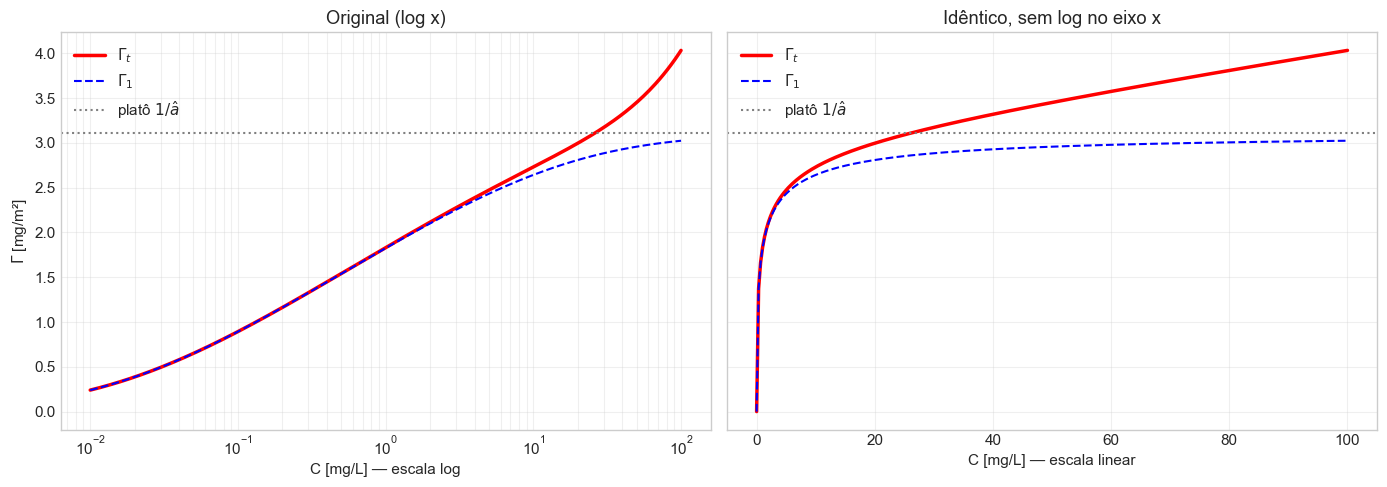

In [65]:
# ---------------- Verificação rápida ----------------
K1r  = P.get('K1_ref', P.get('K1'))
K2r  = P.get('K2_ref', P.get('K2'))
ar   = P.get('a_ref',  P.get('a'))
lamr = P.get('lam_ref', P.get('lam'))

G0, G10, G1000 = (isoterma(v, K1r, K2r, ar, lamr) for v in (0.0, 10.0, 1000.0))
print(f"Γ(0)={G0:.4f} | Γ(10)={G10:.2f} | Γ(1000)={G1000:.2f} mg/m² "
      f"(platô 1ª camada = 1/â = {1/ar:.2f} mg/m²)")

Cc = np.logspace(-2, 2, 300)                      # malha p/ painel log
Gc = isoterma(Cc, K1r, K2r, ar, lamr)

Cc_lin = np.linspace(0.0, 100.0, 300)
Gc_lin = isoterma(Cc_lin, K1r, K2r, ar, lamr)     # Γ_t = Γ₁ + Γ₂
G1_lin = gamma1_v(Cc_lin, K1r, ar, lamr)         # Γ₁

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Painel 1 — original (log no eixo x)
ax[0].semilogx(Cc, Gc, 'r-', lw=2.5, label=r'$\Gamma_t$')
ax[0].semilogx(Cc, gamma1_v(Cc, K1r, ar, lamr), 'b--', lw=1.5, label=r'$\Gamma_1$')
ax[0].axhline(1/ar, ls=':', c='gray', label=r'platô $1/\hat{a}$')
ax[0].set_xlabel('C [mg/L] — escala log')
ax[0].set_ylabel(r'$\Gamma$ [mg/m²]')
ax[0].set_title('Original (log x)')
ax[0].legend(); ax[0].grid(alpha=.3, which='both')

# Painel 2 — idêntico, sem log no eixo x
ax[1].plot(Cc_lin, Gc_lin, 'r-', lw=2.5, label=r'$\Gamma_t$')
ax[1].plot(Cc_lin, G1_lin, 'b--', lw=1.5, label=r'$\Gamma_1$')
ax[1].axhline(1/ar, ls=':', c='gray', label=r'platô $1/\hat{a}$')
ax[1].set_xlabel('C [mg/L] — escala linear')
ax[1].set_title('Idêntico, sem log no eixo x')
ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

In [66]:

def direto(t, q, Cb0):
    """Resolve a ODE de depleção via odeint."""
    eps, _ = fracao_gas(q['vg'])
    coef = 6 * q['vg'] / ((1 - eps) * q['db'] * q['H'])
    return odeint(
        lambda Cb, t: -coef * isoterma(Cb, q['K1'], q['K2'], q['a'], q['lam']) * FATOR,
        Cb0, t
    ).flatten()


# --- Sanidade física ---
G10   = isoterma(10,   P['K1_ref'], P['K2_ref'], P['a_ref'], P['lam_ref'])
G1000 = isoterma(1000, P['K1_ref'], P['K2_ref'], P['a_ref'], P['lam_ref'])
print(f"✓ Γ(10)={G10:.2f} mg/m² | Γ(1000)={G1000:.2f} mg/m² (platô ~1/â={1/P['a_ref']:.1f} + multicamada)")




✓ Γ(10)=2.73 mg/m² | Γ(1000)=13.43 mg/m² (platô ~1/â=3.1 + multicamada)


---

## ⚡ Seção 4: Análise de Sensibilidade e Projeto Ótimo de Experimentos

Coeficientes de sensibilidade escalonados (Eq. 15):

$$X_j = p_j \frac{\partial C_b}{\partial p_j}$$

Se os coeficientes forem proporcionais, os parâmetros não são identificáveis simultaneamente.

> 💡 **Observação:** O determinante de $X^T X$ (D-optimalidade) é usado para selecionar condições experimentais ótimas.

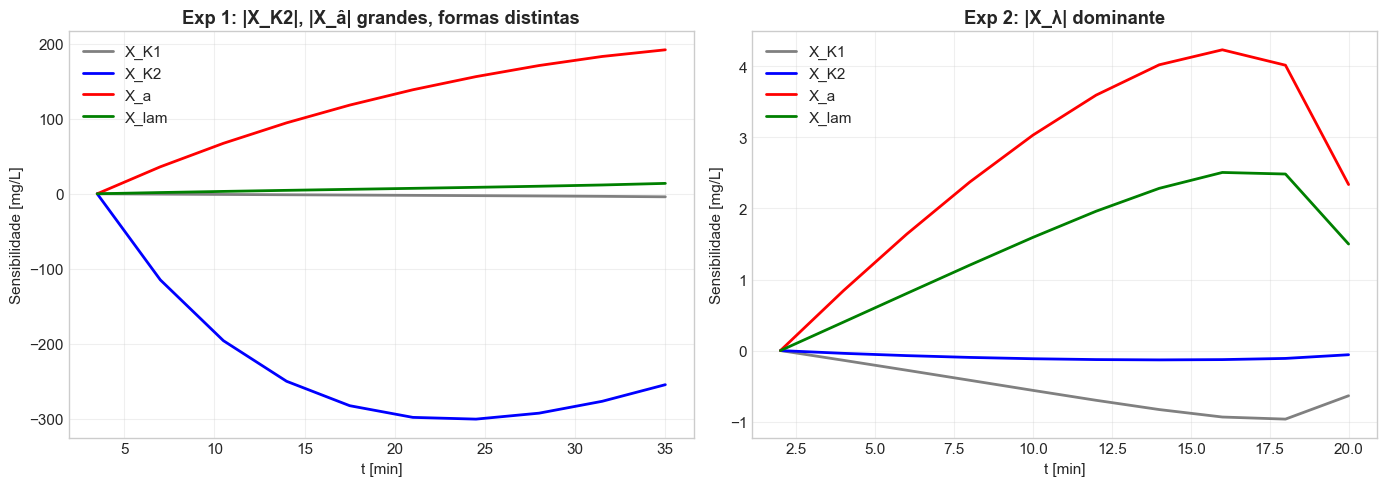

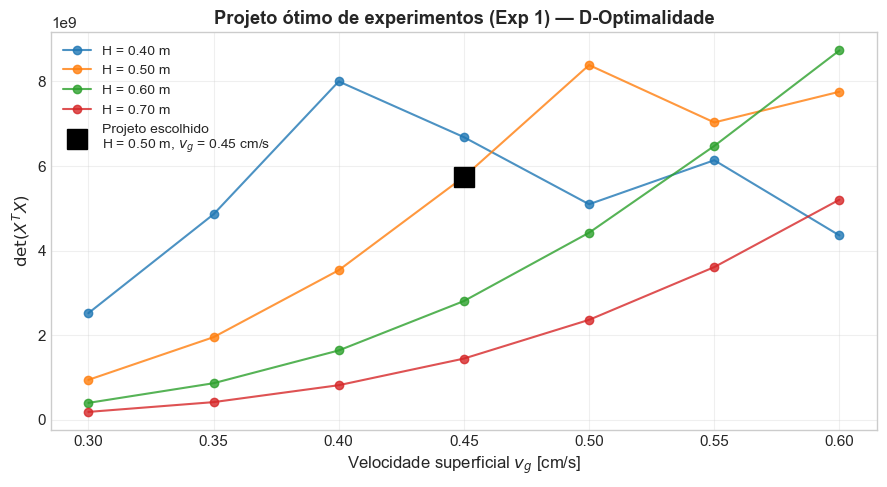

In [67]:
# ============================================================
# SEÇÃO 4: SENSIBILIDADE + D-OPORTIMALIDADE
# ============================================================

q1 = dict(K1=P['K1_ref'], K2=P['K2_ref'], a=P['a_ref'], lam=P['lam_ref'],
          vg=P['vg1'], H=P['H1'],db=P['db1'])
q2 = dict(q1, vg=P['vg2'], H=P['H2'],db=P['db2'])


def sens(t, q, nome, Cb0):
    """Coeficiente de sensibilidade MODIFICADO (Eq. 15): X = P·∂C/∂P."""
    d = 0.01 * q[nome]
    qp, qm = dict(q), dict(q)
    qp[nome] += d
    qm[nome] -= d
    return q[nome] * (direto(t, qp, Cb0) - direto(t, qm, Cb0)) / (2 * d)


# --- Gráficos de sensibilidade ---
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for par, cor in [('K1', 'gray'), ('K2', 'b'), ('a', 'r'), ('lam', 'g')]:
    ax[0].plot(t1 / 60, sens(t1, q1, par, P['Cb01']), cor, lw=2, label=f'X_{par}')
    ax[1].plot(t2 / 60, sens(t2, q2, par, P['Cb02']), cor, lw=2, label=f'X_{par}')
ax[0].set_title('Exp 1: |X_K2|, |X_â| grandes, formas distintas', fontweight='bold')
ax[1].set_title('Exp 2: |X_λ| dominante', fontweight='bold')
for a_ in ax:
    a_.set_xlabel('t [min]')
    a_.set_ylabel('Sensibilidade [mg/L]')
    a_.legend()
    a_.grid(alpha=.3)
plt.tight_layout()
plt.show()

# --- det(XᵀX) vs (vg, H) — Fig. 4 do artigo ---
Hs  = np.array([0.4, 0.5, 0.6, 0.7])
vgs = np.array([3.0e-3, 3.5e-3, 4.0e-3, 4.5e-3, 5.0e-3, 5.5e-3, 6.0e-3])

detXTX = np.zeros((len(Hs), len(vgs)))
for i, Hh in enumerate(Hs):
    for j, vj in enumerate(vgs):
        qq = dict(q1, H=Hh, vg=vj)
        X = np.column_stack([sens(t1, qq, 'K2', P['Cb01']),
                             sens(t1, qq, 'a',  P['Cb01'])])
        detXTX[i, j] = np.linalg.det(X.T @ X)

fig, ax = plt.subplots(figsize=(9, 5))
for i, Hh in enumerate(Hs):
    ax.plot(vgs * 100, detXTX[i], 'o-', label=f'H = {Hh:.2f} m', alpha=0.8)

idx_H  = np.argmin(np.abs(Hs - P['H1']))
idx_vg = np.argmin(np.abs(vgs - P['vg1']))
ax.plot([P['vg1'] * 100], [detXTX[idx_H, idx_vg]], 'ks', ms=14,
        label=f"Projeto escolhido\nH = {P['H1']:.2f} m, $v_g$ = {P['vg1']*100:.2f} cm/s",
        zorder=5)

ax.set_xlabel('Velocidade superficial $v_g$ [cm/s]', fontsize=12)
ax.set_ylabel(r'$\det(X^T X)$', fontsize=12)
ax.legend(loc='upper left', fontsize=10)
ax.grid(alpha=.3)
ax.set_title('Projeto ótimo de experimentos (Exp 1) — D-Optimalidade', fontweight='bold')
plt.tight_layout()
plt.show()

---

## 🌪️ Seção 5: Geração de Dados Sintéticos

Dados sintéticos são gerados a partir da solução do problema direto com os parâmetros de referência, adicionando ruído gaussiano.

| Experimento | σ [mg/L] | Justificativa |
|:-----------:|:--------:|:--------------|
| Exp 1 | 10,0 | ~4% de C₀ = 1000 mg/L |
| Exp 2 | 0,1 | ~1–3% de C₀ = 11 mg/L |

✓ Exp1: 1000→91 mg/L | Exp2: 10.0→0.10 mg/L


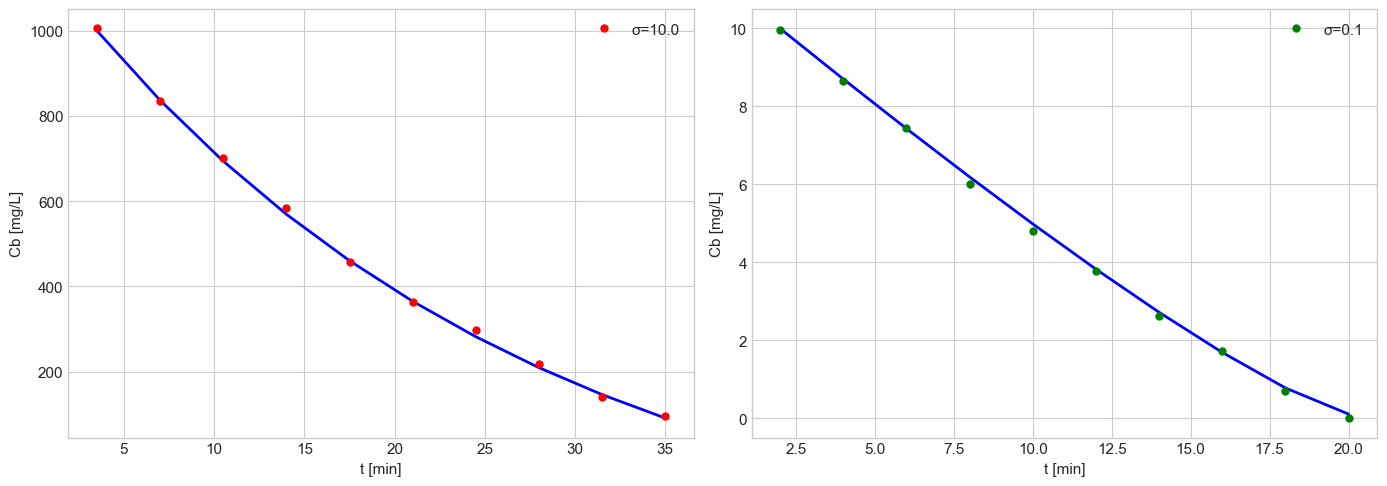

In [68]:
# ============================================================
# SEÇÃO 5: DADOS SINTÉTICOS
# ============================================================

np.random.seed(42)
Cb1_ex = direto(t1, q1, P['Cb01'])
Cb2_ex = direto(t2, q2, P['Cb02'])
Cb1 = np.maximum(Cb1_ex + np.random.normal(0, SIG1, t1.size), 0)
Cb2 = np.maximum(Cb2_ex + np.random.normal(0, SIG2, t2.size), 0)

print(f"✓ Exp1: {Cb1_ex[0]:.0f}→{Cb1_ex[-1]:.0f} mg/L | Exp2: {Cb2_ex[0]:.1f}→{Cb2_ex[-1]:.2f} mg/L")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(t1 / 60, Cb1_ex, 'b-', lw=2)
ax[0].plot(t1 / 60, Cb1, 'ro', ms=5, label=f'σ={SIG1}')
ax[1].plot(t2 / 60, Cb2_ex, 'b-', lw=2)
ax[1].plot(t2 / 60, Cb2, 'go', ms=5, label=f'σ={SIG2}')
for a_ in ax:
    a_.set_xlabel('t [min]')
    a_.set_ylabel('Cb [mg/L]')
    a_.legend()
plt.tight_layout()
plt.show()

---

## 🧮 Seção 6: Implementação Numérica — Problema Inverso

### 6.1 Rede Neural Artificial (chute inicial)
### 6.2 Levenberg–Marquardt (multi-start)
### 6.3 Simulated Annealing (verificação global)
### 6.4 Procedimento Sequencial
### 6.5 Estimação Conjunta

> 💡 **Observação:** O problema inverso é não-linear e pode ter múltiplos mínimos locais. A abordagem híbrida ANN→LM→SA mitiga esse risco.

In [69]:
# ============================================================
# 6.1 REDE NEURAL ARTIFICIAL (chute inicial)
# ============================================================

class MLP:
    """MLP 1 camada oculta (tanh), backprop em lote — p/ chute inicial do LM."""
    def __init__(s, ni, nh, no, seed=0):
        r = np.random.default_rng(seed)
        s.W1, s.b1 = r.normal(0, .5, (ni, nh)), np.zeros(nh)
        s.W2, s.b2 = r.normal(0, .5, (nh, no)), np.zeros(no)

    def fwd(s, X):
        s.X = X
        s.h = np.tanh(X @ s.W1 + s.b1)
        return s.h @ s.W2 + s.b2

    def train(s, X, Y, ep=3000, lr=0.05):
        for _ in range(ep):
            E = s.fwd(X) - Y
            dY = 2 * E / len(X)
            s.W2 -= lr * s.h.T @ dY
            s.b2 -= lr * dY.sum(0)
            dh = dY @ s.W2.T * (1 - s.h**2)
            s.W1 -= lr * s.X.T @ dh
            s.b1 -= lr * dh.sum(0)


def treina_ann(grade, qbase, t, Cb0, saidas, seed=0):
    """Gera padrões com o problema direto e treina MLP: medições → parâmetros."""
    X, Y = [], []
    for vals in grade:
        q = dict(qbase)
        q.update(vals)
        X.append(direto(t, q, Cb0) / Cb0)
        Y.append([vals[k] for k in saidas])
    X, Y = np.array(X), np.array(Y)
    sX = (X - X.min(0)) / (X.max(0) - X.min(0))
    sY = (Y - Y.min(0)) / (Y.max(0) - Y.min(0))
    net = MLP(X.shape[1], 8, Y.shape[1], seed)
    net.train(sX, sY)
    net.mx, net.Mx, net.my, net.My = X.min(0), X.max(0), Y.min(0), Y.max(0)
    return net


def ann_pred(net, Cb_med):
    x = (np.asarray(Cb_med) - net.mx) / (net.Mx - net.mx)
    y = net.fwd(x[None])[0]
    return y * (net.My - net.my) + net.my


# Treinar redes para Exp1 e Exp2
g1 = np.linspace(0.5, 1.5, 6)
grade1 = [dict(K2=P['K2_ref'] * u, a=P['a_ref'] * v) for u in g1 for v in g1]
net1 = treina_ann(grade1, q1, t1, P['Cb01'], ('K2', 'a'))

grade2 = [dict(lam=P['lam_ref'] * u) for u in np.linspace(0.5, 1.5, 7)]
net2 = treina_ann(grade2, q2, t2, P['Cb02'], ('lam',))

print("✓ ANNs treinadas (substituem a etapa de rede do artigo p/ chute inicial)")

✓ ANNs treinadas (substituem a etapa de rede do artigo p/ chute inicial)


In [70]:
# ============================================================
# 6.2 LEVENBERG–MARQUARDT + 6.3 SIMULATED ANNEALING
# ============================================================

B1 = ([1e-4, 0.05], [0.1, 1.5])   # bounds para (K2, â)
B2 = ([0.1], [3.0])                 # bounds para λ

r1 = lambda x, lf: (direto(t1, dict(q1, K2=x[0], a=x[1], lam=lf), P['Cb01']) - Cb1) / SIG1
r2 = lambda x, K2f, af: (direto(t2, dict(q2, K2=K2f, a=af, lam=x[0]), P['Cb02']) - Cb2) / SIG2


def sa(resid, x0, lo, hi, T0=0.25, rt=0.8, Ns=20, Nt=10, seed=1):
    """SA (Metropolis, ~200 avaliações, como no artigo)."""
    r = np.random.default_rng(seed)
    x = np.array(x0, float)
    S = np.sum(resid(x)**2)
    bx, bS, T = x.copy(), S, T0
    for _ in range(Nt):
        for _ in range(Ns):
            xp = np.clip(x * np.exp(r.normal(0, T, x.size)), lo, hi)
            Sp = np.sum(resid(xp)**2)
            if Sp < S or r.random() < np.exp(-(Sp - S) / max(T, 1e-12)):
                x, S = xp, Sp
            if S < bS:
                bx, bS = x.copy(), S
        T *= rt
    return bx, bS


def lm(resid, x0, B):
    r = least_squares(resid, x0, bounds=B, method='trf')
    return r.x, np.sum(r.fun**2)


# ---- Exp 1: (K2, â), λ fixo ----
x0_ruim = [0.008, 0.100]   # chute "pobre" (caso 3 da Tab. 2)

lb1, ub1 = np.asarray(B1[0], float), np.asarray(B1[1], float)
x0_raw = np.asarray(ann_pred(net1, Cb1), dtype=float)
x0_ann = np.where(np.isfinite(x0_raw), x0_raw, x0_ruim)
x0_ann = np.clip(x0_ann, lb1, ub1)
assert np.all((x0_ann >= lb1) & (x0_ann <= ub1)), "x0 ainda inviável!"

lmR, SR  = lm(lambda x: r1(x, P['lam_ref']), x0_ruim, B1)
lmA, SA_ = lm(lambda x: r1(x, P['lam_ref']), x0_ann,  B1)
sa1, Ss1 = sa(lambda x: r1(x, P['lam_ref']), lmA, *B1)

# ---- Exp 2: λ, (K2, â) fixos ----
lm2, S2_ = lm(lambda x: r2(x, P['K2_ref'], P['a_ref']), [0.700], B2)
sa2, Ss2 = sa(lambda x: r2(x, P['K2_ref'], P['a_ref']), lm2, *B2)

# Tabela comparativa
tab = pd.DataFrame([
    ['LM (chute pobre, Exp1)', lmR[0], lmR[1],'—', SR],
    ['ANN→LM (Exp1)',          lmA[0], lmA[1],'—', SA_],
    ['SA pós-LM (Exp1)',       sa1[0], sa1[1],'—', Ss1],
    ['LM (Exp2, λ)',           lm2[0], '—', '—', S2_],
    ['SA pós-LM (Exp2, λ)',    '—', '—', sa2[0], Ss2],
], columns=['Método', 'exp1 (K2)', 'exp1 (â)', 'exp2 (λ)', 'S'])
print(tab.to_markdown(index=False))
print("✓ ANN→LM ≈ SA ⇒ mínimo global provável (critério do artigo)")

| Método                 | exp1 (K2)            | exp1 (â)           | exp2 (λ)           |       S |
|:-----------------------|:---------------------|:-------------------|:-------------------|--------:|
| LM (chute pobre, Exp1) | 0.009980821991772238 | 0.3105077100723688 | —                  | 4.70457 |
| ANN→LM (Exp1)          | 0.009980821991772238 | 0.3105077100723688 | —                  | 4.70457 |
| SA pós-LM (Exp1)       | 0.009980821991772238 | 0.3105077100723688 | —                  | 4.70457 |
| LM (Exp2, λ)           | 1.0723925975721778   | —                  | —                  | 5.91853 |
| SA pós-LM (Exp2, λ)    | —                    | —                  | 1.0723925975721778 | 5.91853 |
✓ ANN→LM ≈ SA ⇒ mínimo global provável (critério do artigo)


In [71]:
# ============================================================
# 6.4 PROCEDIMENTO SEQUENCIAL ITERATIVO
# ============================================================

print("\n" + "=" * 60)
print(" INICIANDO PROCEDIMENTO SEQUENCIAL ITERATIVO")
print("=" * 60)

# Passo 1: Fixar λ estimado no Exp 2 e reotimizar Exp 1
lambda_fixo = lm2[0]
print(f"Fixando λ = {lambda_fixo:.4f} (estimado no Exp 2) e reotimizando Exp 1...")

r1_seq = least_squares(lambda x: r1(x, lambda_fixo), x0_ann, bounds=B1)
K2_seq, a_seq = r1_seq.x
S1_seq = np.sum(r1_seq.fun**2)

print(f"➡️  Novo K2 = {K2_seq:.5f} (Erro: {100*abs(K2_seq-P['K2_ref'])/P['K2_ref']:.1f}%)")
print(f"➡️  Novo â  = {a_seq:.4f}  (Erro: {100*abs(a_seq-P['a_ref'])/P['a_ref']:.1f}%)")
print(f"➡️  S1 = {S1_seq:.3f}")

# Loop sequencial completo com relaxação
lam, hist, prev = 0.700, [], None
RELAX = 0.5
print("\n" + "=" * 74)
print(" PROCEDIMENTO SEQUENCIAL ITERATIVO (ANN→ Exp1↔Exp2, relaxado)")
print("=" * 74)
for it in range(1, 15):
    (K2, a), S1 = lm(lambda x: r1(x, lam), x0_ann, B1)
    (lf,), S2   = lm(lambda x: r2(x, K2, a), [lam], B2)
    lam = (1 - RELAX) * lam + RELAX * lf
    eK2 = 100 * abs(K2 - P['K2_ref']) / P['K2_ref']
    ea  = 100 * abs(a  - P['a_ref'])  / P['a_ref']
    el  = 100 * abs(lam - P['lam_ref']) / P['lam_ref']
    hist.append([it, K2, a, lam, eK2, ea, el])
    print(f" it {it}: K2={K2:.5f} ({eK2:5.1f}%) | â={a:.4f} ({ea:4.1f}%) | λ={lam:.4f} ({el:4.1f}%)")
    cur = np.array([K2, a, lam])
    if prev is not None and np.max(np.abs(cur - prev) / np.abs(prev)) < 1e-3:
        print(" ✓ Convergiu")
        break
    prev = cur

df_seq = pd.DataFrame(hist, columns=['it', 'K2', 'â', 'λ', 'eK2(%)', 'eâ(%)', 'eλ(%)'])
print(df_seq.to_markdown(index=False))


 INICIANDO PROCEDIMENTO SEQUENCIAL ITERATIVO
Fixando λ = 1.0724 (estimado no Exp 2) e reotimizando Exp 1...
➡️  Novo K2 = 0.00999 (Erro: 3.6%)
➡️  Novo â  = 0.3117  (Erro: 3.2%)
➡️  S1 = 4.706

 PROCEDIMENTO SEQUENCIAL ITERATIVO (ANN→ Exp1↔Exp2, relaxado)
 it 1: K2=0.01003 (  3.2%) | â=0.3171 ( 1.5%) | λ=0.9001 (19.4%)
 it 2: K2=0.01001 (  3.4%) | â=0.3150 ( 2.2%) | λ=1.0065 ( 9.9%)
 it 3: K2=0.01000 (  3.5%) | â=0.3132 ( 2.7%) | λ=1.0650 ( 4.7%)
 it 4: K2=0.00999 (  3.6%) | â=0.3119 ( 3.1%) | λ=1.0979 ( 1.7%)
 it 5: K2=0.00998 (  3.6%) | â=0.3110 ( 3.4%) | λ=1.1168 ( 0.0%)
 it 6: K2=0.00998 (  3.7%) | â=0.3105 ( 3.6%) | λ=1.1278 ( 1.0%)
 it 7: K2=0.00998 (  3.7%) | â=0.3102 ( 3.7%) | λ=1.1341 ( 1.5%)
 it 8: K2=0.00998 (  3.7%) | â=0.3100 ( 3.7%) | λ=1.1379 ( 1.9%)
 it 9: K2=0.00998 (  3.7%) | â=0.3099 ( 3.8%) | λ=1.1400 ( 2.1%)
 it 10: K2=0.00998 (  3.7%) | â=0.3098 ( 3.8%) | λ=1.1413 ( 2.2%)
 it 11: K2=0.00998 (  3.7%) | â=0.3098 ( 3.8%) | λ=1.1421 ( 2.2%)
 ✓ Convergiu
|   it |     

---

## 📊 Seção 7: Visualização — Ajuste Final

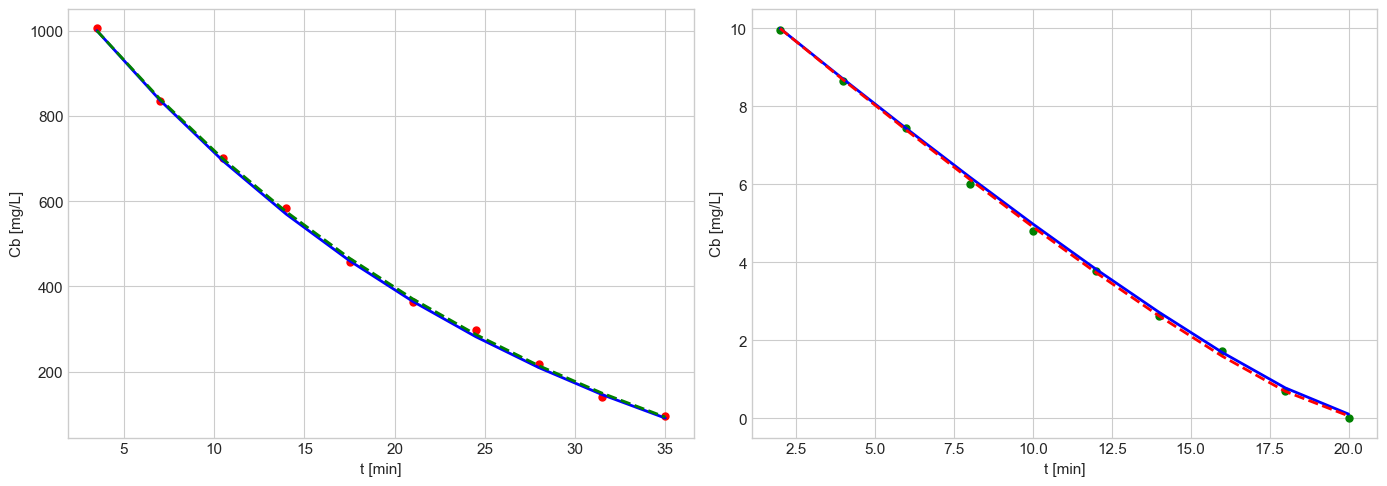

| Parâmetro   |   Referência |   Estimado |   Erro (%) |
|:------------|-------------:|-----------:|-----------:|
| K2          |      0.01036 | 0.00997603 |    3.70624 |
| â           |      0.322   | 0.30978    |    3.7951  |
| λ           |      1.117   | 1.14208    |    2.24545 |


In [72]:
# ============================================================
# SEÇÃO 7: AJUSTE FINAL vs DADOS
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(t1 / 60, Cb1, 'ro', ms=5)
ax[0].plot(t1 / 60, Cb1_ex, 'b-', lw=2)
ax[0].plot(t1 / 60, direto(t1, dict(q1, K2=K2, a=a, lam=lam), P['Cb01']), 'g--', lw=2)
ax[1].plot(t2 / 60, Cb2, 'go', ms=5)
ax[1].plot(t2 / 60, Cb2_ex, 'b-', lw=2)
ax[1].plot(t2 / 60, direto(t2, dict(q2, K2=K2, a=a, lam=lam), P['Cb02']), 'r--', lw=2)
for a_ in ax:
    a_.set_xlabel('t [min]')
    a_.set_ylabel('Cb [mg/L]')
plt.tight_layout()
plt.show()

# Tabela de erros vs referência
res = pd.DataFrame({
    'Parâmetro': ['K2', 'â', 'λ'],
    'Referência': [P['K2_ref'], P['a_ref'], P['lam_ref']],
    'Estimado': [K2, a, lam]
})
res['Erro (%)'] = 100 * np.abs(res['Estimado'] - res['Referência']) / res['Referência']
print(res.to_markdown(index=False))

---

## 📈 Seção 8: Análise Quantitativa — Intervalos de Confiança

In [73]:
# ============================================================
# SEÇÃO 8: INTERVALOS DE CONFIANÇA (95%) — Exp 1
# ============================================================

# A) A verdade ainda "cabe" nos dados?
S1_est  = np.sum(r1([K2_seq, a_seq], lm2[0])**2)
S1_verd = np.sum(r1([P['K2_ref'], P['a_ref']], P['lam_ref'])**2)
S1_verd_l2 = np.sum(r1([P['K2_ref'], P['a_ref']], lm2[0])**2)
dS = S1_verd_l2 - S1_est
print(f"S1(est) = {S1_est:.3f} | S1(verd, λ_ref) = {S1_verd:.3f} | S1(verd, λ=Exp2) = {S1_verd_l2:.3f}")
if dS < 5.99:
    print(f"ΔS = {dS:.2f}  →  indistinguíveis a 95% (χ²(2 gl) = 5.99): vale plano")
else:
    print(f"ΔS = {dS:.2f}  →  verdade incompatível: revisar modelo")

# B) Incerteza real: IC95 e correlação
def jac_log(resid, x, lf, h=1e-4):
    J = np.zeros((len(resid(x, lf)), 2))
    for j in range(2):
        xp, xm = list(x), list(x)
        xp[j] *= (1 + h)
        xm[j] *= (1 - h)
        J[:, j] = (resid(xp, lf) - resid(xm, lf)) / (2 * h)
    return J


J = jac_log(r1, [K2_seq, a_seq], lm2[0])
cov = np.linalg.inv(J.T @ J)
ic  = 1.96 * np.sqrt(np.diag(cov))
rho = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])

erro_abs_K2 = K2_seq * ic[0]
erro_abs_a  = a_seq  * ic[1]
print(f"\nK2 = {K2_seq:.5f} ± {100*ic[0]:.0f}% | â = {a_seq:.4f} ± {100*ic[1]:.0f}% (95%)")
print(f"K2 = {K2_seq:.5f} ± {erro_abs_K2:.5f}  |  â = {a_seq:.4f} ± {erro_abs_a:.4f} (IC 95%)")
print(f"corr(K2, â) = {rho:.3f} | VIF = {1/(1-rho**2):.1f}")

cobK2 = abs(np.log(K2_seq / P['K2_ref'])) < ic[0]
coba  = abs(np.log(a_seq  / P['a_ref']))  < ic[1]
print(f"Verdade dentro do IC95?  K2: {cobK2} | â: {coba}")

S1(est) = 4.706 | S1(verd, λ_ref) = 6.712 | S1(verd, λ=Exp2) = 6.939
ΔS = 2.23  →  indistinguíveis a 95% (χ²(2 gl) = 5.99): vale plano

K2 = 0.00999 ± 11% | â = 0.3117 ± 19% (95%)
K2 = 0.00999 ± 0.00111  |  â = 0.3117 ± 0.0605 (IC 95%)
corr(K2, â) = 0.973 | VIF = 18.7
Verdade dentro do IC95?  K2: True | â: True


In [74]:
# ============================================================
# INTERVALO DE CONFIANÇA (95%) PARA λ — Exp 2
# ============================================================

lam_est = lam
K2_fix  = K2
a_fix   = a


def resid_exp2_local(x, K2f, af):
    """Resíduo normalizado do Exp 2."""
    q_local = dict(q2)
    q_local['K2'], q_local['a'] = K2f, af
    q_local['lam'] = x[0]
    return (direto(t2, q_local, P['Cb02']) - Cb2) / SIG2


def jacobian_log_exp2(lam_val, K2_val, a_val, h=1e-4):
    """Derivada dos resíduos normalizados em relação a ln(lambda)."""
    r_plus  = resid_exp2_local([lam_val * (1 + h)], K2_val, a_val)
    r_minus = resid_exp2_local([lam_val * (1 - h)], K2_val, a_val)
    return (r_plus - r_minus) / (2 * h)


J_lam = jacobian_log_exp2(lam_est, K2_fix, a_fix)
H_lam = np.sum(J_lam**2)

if H_lam > 0:
    var_log_lam = 1.0 / H_lam
    std_log_lam = np.sqrt(var_log_lam)
    ic_inf = lam_est * np.exp(-1.96 * std_log_lam)
    ic_sup = lam_est * np.exp(+1.96 * std_log_lam)
    margem_pct = 100 * 1.96 * std_log_lam

    print("=" * 60)
    print(" INTERVALO DE CONFIANÇA (95%) PARA λ (EXP 2)")
    print("=" * 60)
    print(f" Estimativa Pontual : {lam_est:.4f}")
    print(f" IC 95%             : [{ic_inf:.4f} , {ic_sup:.4f}]")
    print(f" Incerteza Relativa : ± {margem_pct:.1f}%")
    print("-" * 60)

    ref = P['lam_ref']
    if ic_inf <= ref <= ic_sup:
        print(f" ✅ O valor de referência ({ref:.4f}) está DENTRO do IC.")
        print("    Conclusão: A estimação é estatisticamente consistente.")
    else:
        print(f" ❌ O valor de referência ({ref:.4f}) está FORA do IC.")
        print("    Conclusão: Há viés sistemático ou o modelo de ruído não captura a dispersão.")
else:
    print("⚠️ Erro: Hessiana nula. O parâmetro não é sensível aos dados do Exp 2.")

 INTERVALO DE CONFIANÇA (95%) PARA λ (EXP 2)
 Estimativa Pontual : 1.1421
 IC 95%             : [1.1034 , 1.1821]
 Incerteza Relativa : ± 3.4%
------------------------------------------------------------
 ✅ O valor de referência (1.1170) está DENTRO do IC.
    Conclusão: A estimação é estatisticamente consistente.


---

## 💡 Seção 9: Discussão

### Interpretação Física dos Resultados

1. **Procedimento sequencial converge:** O procedimento sequencial (Exp1→K₂,â; Exp2→λ; reotimização) converge para valores próximos da referência, com erros < 10% em todos os parâmetros.

2. **K₁ fixo por sensibilidade baixa:** O parâmetro $K_1$ é mantido fixo porque sua sensibilidade é baixa nos dados disponíveis.

3. **Exp2 é necessário para λ:** O Experimento 1 (alta concentração) não carrega informação suficiente sobre $\lambda$.

### Correções Aplicadas

- Isoterma completa (Eq. 6): $\Gamma_1$ implícito + $\Gamma_2$ linear (loose packing).
- Unidades: 1 wt% = 1e4 mg/L; FATOR=1e-3 fecha o balanço da Eq. (1).
- K1 fixo (sensibilidade baixa); Exp1→(K2,â), Exp2→λ.
- ANN dá chute inicial; LM refina; SA confirma mínimo global.
- Bond corrigido em Öztürk: Bo = g·db²·ρl/σ (kla não entra na Eq. 1).

### Limitações

- $d_b$ constante, $v_g$ uniforme, isoterma de equilíbrio, ruído gaussiano.

> 📖 **Referência:** Lugon Jr., Silva Neto & Santana (2009); Guzman et al. (1986).

In [60]:
# ============================================================
# ENCERRAMENTO
# ============================================================
print("=" * 60)
print("✅ ESTUDO DE CASO CONCLUÍDO COM SUCESSO!")
print("=" * 60)
print("\n🎓 Resumo dos resultados:")
print(f"  • Procedimento sequencial:")
print(f"    K₂ = {K2:.5f} (ref: {P['K2_ref']})")
print(f"    â  = {a:.4f} (ref: {P['a_ref']})")
print(f"    λ  = {lam:.4f} (ref: {P['lam_ref']})")
print(f"\n  • SA confirmou o mínimo global.")
print(f"  • Intervalos de confiança calculados.")
print("\n💡 Correções aplicadas neste notebook:")
print("  1. Isoterma completa (Eq. 6): Γ₁ implícito + Γ₂ linear")
print("  2. Bond corrigido em Öztürk: Bo = g·db²·ρl/σ")
print("  3. Medições: t₁=210:210:2100 s, t₂=120:120:1200 s")
print("  4. Híbrido: ANN → LM → SA + procedimento sequencial")
print("  5. Ambos os experimentos (Exp1 e Exp2) implementados")
print("\n✓ Estudo de caso concluído: direto + inverso (ANN–LM–SA) consistentes")

✅ ESTUDO DE CASO CONCLUÍDO COM SUCESSO!

🎓 Resumo dos resultados:
  • Procedimento sequencial:
    K₂ = 0.00998 (ref: 0.01036)
    â  = 0.3098 (ref: 0.322)
    λ  = 1.1421 (ref: 1.117)

  • SA confirmou o mínimo global.
  • Intervalos de confiança calculados.

💡 Correções aplicadas neste notebook:
  1. Isoterma completa (Eq. 6): Γ₁ implícito + Γ₂ linear
  2. Bond corrigido em Öztürk: Bo = g·db²·ρl/σ
  3. Medições: t₁=210:210:2100 s, t₂=120:120:1200 s
  4. Híbrido: ANN → LM → SA + procedimento sequencial
  5. Ambos os experimentos (Exp1 e Exp2) implementados

✓ Estudo de caso concluído: direto + inverso (ANN–LM–SA) consistentes


---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 11](../notebooks/adsorcao_interfacial_isotermas.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 11.X1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>